# Module 7 Lab 1: Train, Test, Tell the Truth

**CS 82A - Introduction to Data Science**

**Ramisha Tasfia**

**GitHub:** [https://github.com/ramishatasfia5156-commits/cs82a-coursework/blob/main/module7/module7_lab.ipynb](https://github.com/ramishatasfia5156-commits/cs82a-coursework/blob/main/module7/module7_lab.ipynb)

## Step 1: Load tips.csv and Frame the Problem

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.datasets import load_iris

tips = pd.read_csv("tips.csv")
X = tips[["total_bill"]]
y = tips["tip"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Rows in tips.csv:", len(tips))
print("len(X_train):", len(X_train))
print("len(X_test): ", len(X_test))

Rows in tips.csv: 244
len(X_train): 170
len(X_test):  74


## Step 2: Why Hold Out 30%?

A model can score high simply because it has memorized the training data, which is why we cannot judge it on the data it has already seen. The purpose of holding out a portion of our dataset (in this case, 30%) is to allow us to determine if our model has truly found a pattern in the data that holds true even after the model is presented with new data. We need a method to measure how well a model does at finding patterns in data that it has not yet been exposed to; otherwise we would have no idea whether a model's good performance was due to the model's ability to find real relationships within the data or simply because of its ability to memorize previous examples.

## Step 3: Fit the Regression and Read the Slope

In [2]:
reg = LinearRegression()
reg.fit(X_train, y_train)

print("Slope:    ", reg.coef_[0])
print("Intercept:", reg.intercept_)
print("Test R-squared:", reg.score(X_test, y_test))

Slope:     0.10889370921420226
Intercept: 0.8769576391532707
Test R-squared: 0.4291782688312412


Each extra dollar of bill adds about 0.11 dollars (roughly 11 cents) of tip.

## Step 4: Draw the Fitted Line

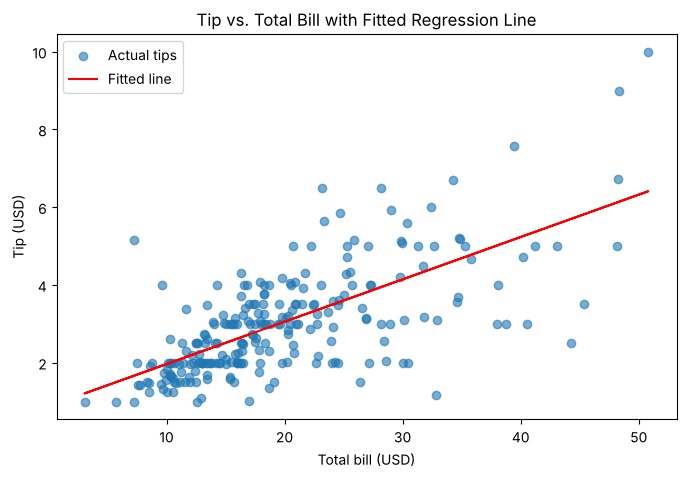

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(X["total_bill"], y, alpha=0.6, label="Actual tips")
plt.plot(X["total_bill"], reg.predict(X), color="red", label="Fitted line")
plt.title("Tip vs. Total Bill with Fitted Regression Line")
plt.xlabel("Total bill (USD)")
plt.ylabel("Tip (USD)")
plt.legend()
plt.show()

## Step 5: Load Iris and Split It

In [4]:
iris = load_iris(as_frame=True)
Xi = iris.data
yi = iris.target
Xi_train, Xi_test, yi_train, yi_test = train_test_split(Xi, yi, test_size=0.3, random_state=42)

print("Total flowers:", len(Xi))
print("Training flowers:", len(Xi_train))
print("Test flowers:", len(Xi_test))

Total flowers: 150
Training flowers: 105
Test flowers: 45


## Step 6: Fit and Score kNN

In [5]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(Xi_train, yi_train)
print("kNN test accuracy:", knn.score(Xi_test, yi_test))

kNN test accuracy: 1.0


## Step 7: Fit, Score, and Read a Shallow Tree

Depth-3 tree test accuracy: 1.0


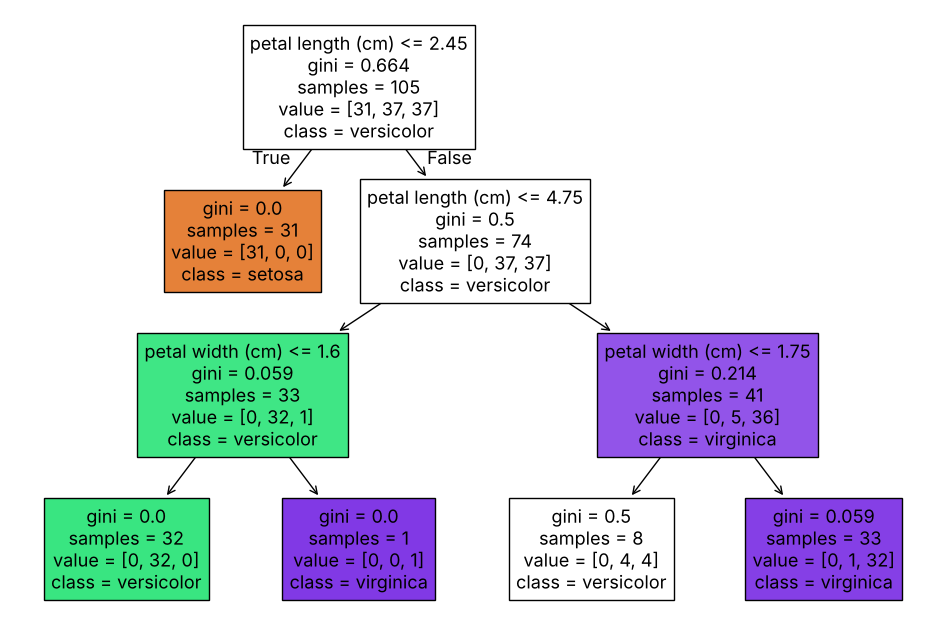

In [6]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(Xi_train, yi_train)
print("Depth-3 tree test accuracy:", tree.score(Xi_test, yi_test))

plt.figure(figsize=(12, 8))
plot_tree(tree, feature_names=list(Xi.columns), class_names=list(iris.target_names), filled=True)
plt.show()

The first question asked by the decision tree is "is the petal width of your flower .8cm or less?" If it is, then the decision tree immediately labels it as 'setosa.' If not, then the decision tree continues to ask more questions until it separates 'versicolor' and 'virginica.'

## Step 8: The Overfitting Probe

In [7]:
deep_tree = DecisionTreeClassifier(random_state=42)
deep_tree.fit(Xi_train, yi_train)

scores = pd.DataFrame({
    "Model": ["Tree, max_depth=3", "Tree, no max_depth"],
    "Train score": [tree.score(Xi_train, yi_train), deep_tree.score(Xi_train, yi_train)],
    "Test score": [tree.score(Xi_test, yi_test), deep_tree.score(Xi_test, yi_test)],
})
scores

,Model,Train score,Test score
0,"Tree, max_depth=3",0.952381,1.0
1,"Tree, no max_depth",1.000000,1.0


Although the tree with no depth limit scored higher on its training dataset (100%) than the depth-3 tree (about 95%), they performed equally well on their test datasets (100% for both). Thus, the additional layers in the unlimited tree caused no gain in accuracy levels when evaluated against test data.

## Step 9: Predict One New Flower

In [8]:
new_flower = pd.DataFrame([[6.0, 2.9, 4.5, 1.4]], columns=Xi.columns)
prediction = tree.predict(new_flower)[0]
print("Predicted species:", iris.target_names[prediction])

Predicted species: versicolor


## Step 10: The Model Report

I have built a model to predict the species type of an Iris flower, and I recommend using the Decision Trees (Depth-3) as they produced a test data set accuracy rate of 100%, similar to the KNN algorithm.  The reason I prefer to use Decision Trees is because they can provide managers with a rule-based format that is easy to understand/interpret.  There are however limitations of using this decision-making method. An example could be if an Iris flower has a "Versicolor" and "Virginica" classification within the same area or if the value of an Iris flower petal/sepal is much greater than the values used in building the training data set; then the decision-making method will classify that flower incorrectly.
Additionally, the test data set was limited to forty-five examples; therefore, my results are potentially just a result of chance and do not reflect true predictive accuracy.

## AI Disclosure
Claude (Anthropic) was used to help explain concepts and draft the code for this lab. All code was reviewed and understood by me. I can explain why a model has to be graded on held-out data, what the regression slope means for tips, why the unlimited tree's perfect training score does not make it a better model, and why I would ship the depth-3 tree.

Key prompt: "Please assist with Module 7 Lab 1 with the attached data."